In [56]:
import os
import numpy as np
import torch
import pytorch_lightning as pl
import torchmetrics

from dvclive.lightning import DVCLiveLogger

In [57]:
data_path = "fra.txt"
seed = 423
num_samples = 1000
batch_size = 64

In [58]:
# Vectorize the data.
input_texts = []
target_texts = []
input_characters = set()
target_characters = set()
with open(data_path, "r", encoding="utf-8") as f:
    lines = f.read().split("\n")[:-1]
np.random.seed(seed)
np.random.shuffle(lines)
for line in lines[: min(num_samples, len(lines) - 1)]:
    input_text, target_text, _ = line.split("\t")
    for char in input_text:
        if char not in input_characters:
            input_characters.add(char)
    for char in target_text:
        if char not in target_characters:
            target_characters.add(char)
    # We use "tab" as the "start sequence" character
    # for the targets, and "\n" as "end sequence" character.
    target_text = "\t" + target_text + "\n"
    input_texts.append(input_text)
    target_texts.append(target_text)

input_characters = sorted(list(input_characters))
target_characters = sorted(list(target_characters)) + ["\t", "\n"]
num_encoder_tokens = len(input_characters)
num_decoder_tokens = len(target_characters)
max_encoder_seq_length = max([len(txt) for txt in input_texts])
max_decoder_seq_length = max([len(txt) for txt in target_texts])

print("Number of samples:", len(input_texts))
print("Number of unique input tokens:", num_encoder_tokens)
print("Number of unique output tokens:", num_decoder_tokens)
print("Max sequence length for inputs:", max_encoder_seq_length)
print("Max sequence length for outputs:", max_decoder_seq_length)

input_token_index = dict([(char, i) for i, char in enumerate(input_characters)])
target_token_index = dict([(char, i) for i, char in enumerate(target_characters)])

encoder_input_data = np.zeros(
    (len(input_texts), max_encoder_seq_length), dtype=int
)
decoder_input_data = np.zeros(
    (len(input_texts), max_decoder_seq_length), dtype=int
)
decoder_target_data = np.zeros(
    (len(input_texts), max_decoder_seq_length), dtype=int
)

for i, (input_text, target_text) in enumerate(zip(input_texts, target_texts)):
    for t, char in enumerate(input_text):
        encoder_input_data[i, t] = input_token_index[char]
    encoder_input_data[i, t + 1 :] = input_token_index[" "]
    for t, char in enumerate(target_text):
        # decoder_target_data is ahead of decoder_input_data by one timestep
        decoder_input_data[i, t] = target_token_index[char]
        if t > 0:
            # decoder_target_data will be ahead by one timestep
            # and will not include the start character.
            decoder_target_data[i, t - 1] = target_token_index[char]
    decoder_input_data[i, t + 1 :] = target_token_index[" "]
    decoder_target_data[i, t:] = target_token_index[" "]

Number of samples: 1000
Number of unique input tokens: 65
Number of unique output tokens: 86
Max sequence length for inputs: 102
Max sequence length for outputs: 121


In [59]:
# Define the model 
class LSTMSeqToSeq(pl.LightningModule):
    def __init__(self, latent_dim=8, optim_params={}):
        super().__init__()
        self.save_hyperparameters()
        self.encoder_embedding = torch.nn.Embedding(num_encoder_tokens, self.hparams.latent_dim)
        self.encoder = torch.nn.LSTM(self.hparams.latent_dim, self.hparams.latent_dim, batch_first=True)
        self.decoder_embedding = torch.nn.Embedding(num_decoder_tokens,
                self.hparams.latent_dim)
        self.decoder = torch.nn.LSTM(self.hparams.latent_dim, self.hparams.latent_dim, batch_first=True)

        self.out = torch.nn.Linear(self.hparams.latent_dim, num_decoder_tokens)
        self.acc = torchmetrics.classification.MulticlassAccuracy(
                num_decoder_tokens, average="macro")

    def forward(self, x_encoder, x_decoder):
        encoder_embedded = self.encoder_embedding(x_encoder)
        encoder_outputs, (state_h, state_c) = self.encoder(encoder_embedded)
        decoder_embedded = self.decoder_embedding(x_decoder)
        # We discard `encoder_outputs` and only keep the states.
        decoder_outputs, (_, _) = self.decoder(decoder_embedded, (state_h, state_c))
        out = self.out(decoder_outputs)
        return out

    def training_step(self, batch, batch_idx):
        (x_encoder, x_decoder), y = batch
        out = self(x_encoder, x_decoder)
        # Reshape each step
        y = y.flatten()
        out = out.flatten(end_dim=1)
        # Log metrics
        loss = torch.nn.functional.cross_entropy(out, y)
        acc = self.acc(out, y)
        self.log("train_loss", loss, on_step=True, on_epoch=True)
        self.log("train_acc", acc, on_step=True, on_epoch=True)
        return loss

    def validation_step(self, batch, batch_idx):
        (x_encoder, x_decoder), y = batch
        out = self(x_encoder, x_decoder)
        # Reshape each step
        y = y.flatten()
        out = out.flatten(end_dim=1)
        # Log metrics
        loss = torch.nn.functional.cross_entropy(out, y)
        acc = self.acc(out, y)
        self.log("val_loss", loss, on_step=False, on_epoch=True)
        self.log("val_acc", acc, on_step=False, on_epoch=True)

    def configure_optimizers(self):
        optimizer = torch.optim.RMSprop(self.parameters(), **self.hparams.optim_params)
        return optimizer

In [60]:
# load the data
class CustomDataset(torch.utils.data.Dataset):
    def __init__(self, encoder_input_data, decoder_input_data,
            decoder_target_data):
        self.encoder_input_data = encoder_input_data
        self.decoder_input_data = decoder_input_data
        self.decoder_target_data = decoder_target_data

    def __len__(self):
        return len(self.encoder_input_data)

    def __getitem__(self, idx):
        return (self.encoder_input_data[idx], self.decoder_input_data[idx]), \
               self.decoder_target_data[idx]


combined_data = CustomDataset(encoder_input_data, decoder_input_data, decoder_target_data)
train_len = int(len(combined_data)*0.8)
val_len = len(combined_data) - train_len
train, val = torch.utils.data.random_split(combined_data, [train_len, val_len],
        generator=torch.Generator().manual_seed(seed))
train_loader = torch.utils.data.DataLoader(train, batch_size=batch_size)
val_loader = torch.utils.data.DataLoader(val, batch_size=batch_size)

# DVC Report

params.yaml

|   optim_params.lr |   optim_params.momentum |   latent_dim |
|-------------------|-------------------------|--------------|
|             0.001 |                    0.01 |           32 |

metrics.json

|   val.loss |   val.acc |   epoch |   step |   train.epoch.loss |   train.epoch.acc |   train.step.loss |   train.step.acc |
|------------|-----------|---------|--------|--------------------|-------------------|-------------------|------------------|
|    1.05531 | 0.0116396 |       4 |     64 |            1.01537 |         0.0116458 |           1.01782 |        0.0116279 |

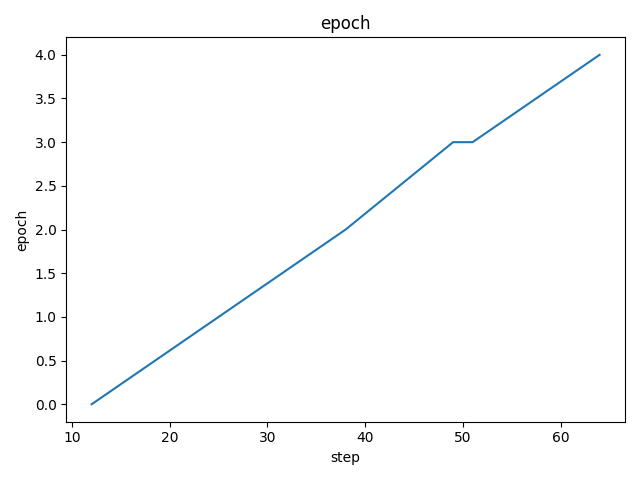

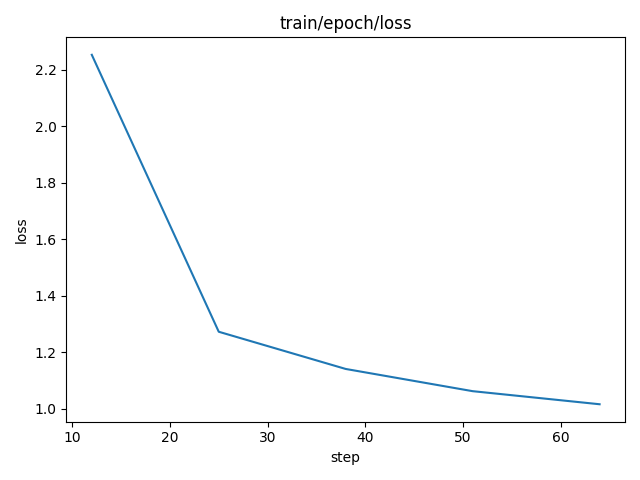

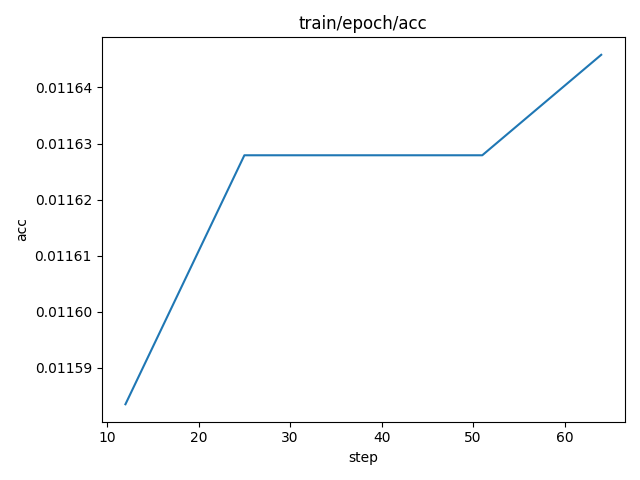

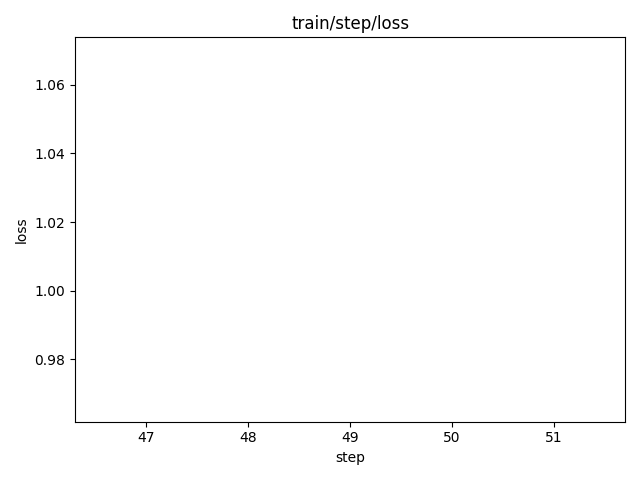

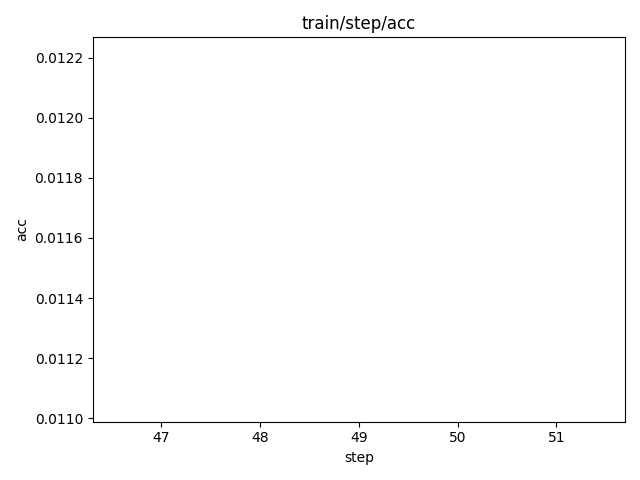

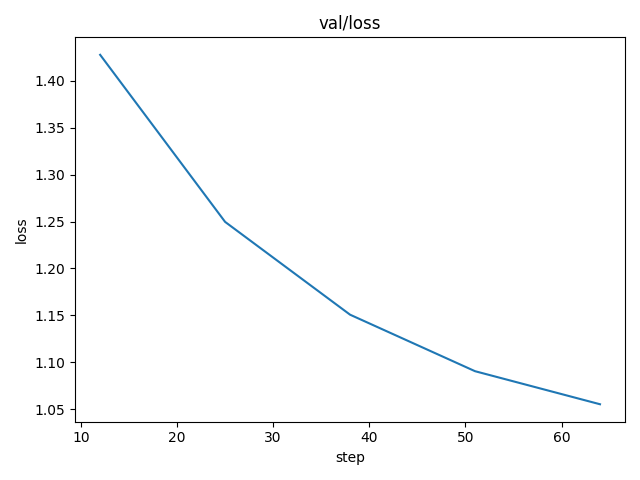

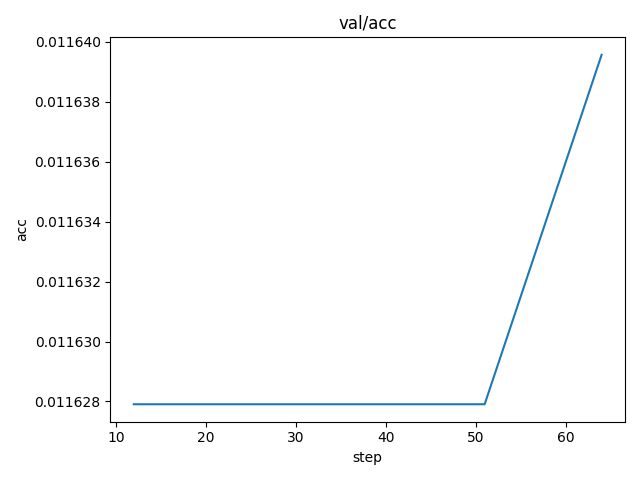


GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs

  | Name              | Type               | Params
---------------------------------------------------------
0 | encoder_embedding | Embedding          | 2.1 K 
1 | encoder           | LSTM               | 8.4 K 
2 | decoder_embedding | Embedding          | 2.8 K 
3 | decoder           | LSTM               | 8.4 K 
4 | out               | Linear             | 2.8 K 
5 | acc               | MulticlassAccuracy | 0     
---------------------------------------------------------
24.6 K    Trainable params
0         Non-trainable params
24.6 K    Total params
0.098     Total estimated model params size (MB)


Epoch 0:  76%|███████▋  | 13/17 [00:03<00:01,  3.26it/s, loss=2.21, v_num=_run]
Validation: 0it [00:00, ?it/s]
Epoch 1:  76%|███████▋  | 13/17 [00:03<00:01,  3.53it/s, loss=1.36, v_num=_run]
Validation: 0it [00:00, ?it/s]
Epoch 2:  76%|███████▋  | 13/17 [00:02<00:00,  4.89it/s, loss=1.16, v_num=_run]
Validation: 0it [00:00, ?it/s]
Epoch 3:  76%|███████▋  | 13/17 [00:06<00:02,  1.90it/s, loss=1.07, v_num=_run]
Validation: 0it [00:00, ?it/s]
Epoch 4:  76%|███████▋  | 13/17 [00:03<00:00,  4.31it/s, loss=1.02, v_num=_run]
Validation: 0it [00:00, ?it/s]
Epoch 4: 100%|██████████| 17/17 [00:07<00:00,  2.30it/s, loss=1.02, v_num=_run]

`Trainer.fit` stopped: `max_epochs=5` reached.


Epoch 4: 100%|██████████| 17/17 [00:10<00:00,  1.61it/s, loss=1.02, v_num=_run]


	DvcLiveLogger/dvclive_run/checkpoints/epoch=4-step=65-v2.ckpt, DvcLiveLogger/dvclive_run/checkpoints/epoch=9-step=70.ckpt, DvcLiveLogger/dvclive_run/checkpoints/epoch=9-step=40.ckpt, DvcLiveLogger/dvclive_run/checkpoints/epoch=9-step=130-v1.ckpt, DvcLiveLogger/dvclive_run/checkpoints/epoch=9-step=130.ckpt, DvcLiveLogger/dvclive_run/checkpoints/epoch=9-step=20.ckpt, DvcLiveLogger/dvclive_run/checkpoints/epoch=4-step=65.ckpt, DvcLiveLogger/dvclive_run/checkpoints/epoch=9-step=130-v3.ckpt, DvcLiveLogger/dvclive_run/checkpoints/epoch=9-step=130-v2.ckpt, DvcLiveLogger/dvclive_run/checkpoints/epoch=1-step=126.ckpt, DvcLiveLogger/dvclive_run/checkpoints/epoch=9-step=70-v1.ckpt, DvcLiveLogger/dvclive_run/checkpoints/epoch=4-step=65-v1.ckpt, DvcLiveLogger/dvclive_run/checkpoints/epoch=4-step=35.ckpt, DvcLiveLogger/dvclive_run/checkpoints/epoch=9-step=130-v4.ckpt, DvcLiveLogger/results/checkpoints/epoch=9-step=130.ckpt, dvclive/dvc.yaml


In [62]:
# train the model
arch = LSTMSeqToSeq(
    latent_dim=32,
    optim_params={
        "lr": 0.001,
        "momentum": 0.01
    }
)

live = DVCLiveLogger(dir="results", save_dvc_exp=True, report="notebook")

trainer = pl.Trainer(max_epochs=10, logger=[live])
trainer.fit(model=arch, train_dataloaders=train_loader,
        val_dataloaders=val_loader)